# BetaPPO Gray84 · GAE와 3-step TD 비교
두 실험은 동일한 84×84 휘도 입력을 사용합니다. `TD_STEPS=0`은 기존 GAE, `TD_STEPS=3`은 3-step return으로 actor advantage와 critic target을 계산합니다. 설정 셀에서 선택한 후 위에서부터 실행하세요. 두 실행의 Drive 경로와 체크포인트는 분리됩니다.

3-step은 학습 중 미래 보상을 반영합니다. 평가 중에는 과거·현재 프레임만 입력됩니다. 프레임 스킵 4에서 3번의 정책 결정은 정상 구간 기준 원본 12프레임입니다.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 1. 코드 준비
공식 합본 ZIP을 업로드합니다. 정책은 RGB에서 유래한 관측만 사용합니다.

In [2]:
import os, sys, subprocess, hashlib, zipfile, shutil
from pathlib import Path
from google.colab import drive, files

os.environ['SDL_VIDEODRIVER'] = 'dummy'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
TD_STEPS = 0  # 0 = GAE baseline, 3 = 3-step TD
VARIANTS = {0: 'gae', 3: 'td3'}
variant = VARIANTS[TD_STEPS]
root = Path('/content/beta_ppo_gray84_' + variant)
run = Path('/content/drive/MyDrive/CarRacing') / f'BetaPPO_Gray84_s42_{variant}'
zip_path = Path('/content/carracing_competition.zip')
if not zip_path.is_file():
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('공식 ZIP 하나를 선택하세요.')
    zip_path.write_bytes(next(iter(uploaded.values())))
manifest = {'agents/actor_critic.py': 'd25aa847bf5d9c0c9803c0016849f2d9bae410caeecf0d943fba8fd695c02037', 'agents/base.py': 'f183f1e46745a9abb5e7f0fc88a08be134104f599326f57ac9bc7f63a324e743', 'agents/dqn.py': '37d7168f7bcb252eff69aab561e85c5ab3d73f01007f6ab95ab00d60fd0d5415', 'agents/__init__.py': '215cd1e434eaf15791c2c826380c5eab6844225ce7b5b9e134894eefd52edc59', 'buffers.py': '59b576518a9997a51f2811f00c8c900394dba24f45d6fb8eaa05f0324da018f1', 'check_submission.py': '7a62312300656f891d1aeffdcab249c501de0153567138f027e8491998763a02', 'envs.py': 'ceee2d847af1a3a498c6b7f0f83f3561b24ac22e53de8bded43c97a15af645d0', 'evaluate.py': '219d4c3ded5b8624d8e4f69d3c71e27145aed6b9eb20dc0ef8b0f9c2355c2574', 'export.py': 'dbd9fe51c3046d2d5a458ad8ea464e99cde777c13be7d8406bf2f667b05f8a6f', 'networks.py': '05c5c6dbd6f4ce2fbfe2a71ef18f84d175ff7a7ff36540c9172f750f27b2b3d8', 'README.md': 'f4b928b8d1ae7f907d21670f5d5c0fe6050845f056ab567ab7b18968608a86b0', 'requirements.txt': 'b38b63f4f8d53b8edce022020a26886d6f079d3484d16d3eb630e530fd11b9b7', 'train.py': '579b46fbf559233490bd3e0949b29880dfe564d890e15c37ba99db7a2344b6b1'}
with zipfile.ZipFile(zip_path) as archive:
    for name, digest in manifest.items():
        data = archive.read('carracing_competition/' + name)
        if hashlib.sha256(data).hexdigest() != digest:
            raise ValueError(f'공식 배포본 버전을 확인하세요: {name}')
        dest = root / name
        dest.parent.mkdir(parents=True, exist_ok=True)
        dest.write_bytes(data)
os.chdir(root)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
# Resample the full field of view with the same pixel indices in NumPy and ONNX.
env_file = root/'envs.py'
original_env = env_file.read_text()
edits = [
    ('N_STACK = 4', 'GRAY84_INDEX = (np.arange(84) * 96 + 48) // 84\nN_STACK = 4'),
    ('        h, w, _ = env.observation_space.shape\n        self.observation_space = gym.spaces.Box(0, 255, (h, w), np.uint8)',
     '        self.observation_space = gym.spaces.Box(0, 255, (84, 84), np.uint8)'),
    ('return gray.astype(np.uint8)', 'return gray[GRAY84_INDEX[:, None], GRAY84_INDEX].astype(np.uint8)'),
    ('return gray.floor().to(torch.uint8)', 'idx = torch.as_tensor(GRAY84_INDEX, device=gray.device)\n    return gray.index_select(-2, idx).index_select(-1, idx).floor().to(torch.uint8)'),
    ('-> (96, 96) uint8 흑백', '-> (84, 84) uint8 흑백'),
    ('여기서는 (B, N_STACK, 96, 96) uint8', '여기서는 (B, N_STACK, 84, 84) uint8'),
]
for old, new in edits:
    assert original_env.count(old) == 1, old
    original_env = original_env.replace(old, new)
env_file.write_text(original_env)


Saving carracing_competition.zip to carracing_competition.zip


5700

In [3]:
import pandas as pd

def recovery_events(trace):
    rows = []
    entries = trace.loc[trace.event.eq('grass_entry'), 'frame'].tolist()
    for i, start in enumerate(entries):
        stop = entries[i+1] - 1 if i+1 < len(entries) else int(trace.frame.max())
        window = trace[trace.frame.between(start, stop)]
        back = window.loc[window.event.eq('road_return'), 'frame']
        gains = window.iloc[:0]
        if len(back):
            gains = window[window.frame.ge(back.iloc[0]) & window.offroad_hint.eq(0)
                           & window.new_tiles.gt(0)]
        resumed = len(gains) >= 3
        rows.append(dict(seed=int(trace.seed.iloc[0]), entry_frame=start,
                         video_s=(start-1)/50, returned=int(len(back)>0),
                         progress_resumed=int(resumed),
                         frames_to_progress=int(gains.frame.iloc[2]-start) if resumed else None))
    return rows


In [4]:
%%writefile agents/beta_ppo.py
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Beta
from agents.base import Agent
from networks import CNNEncoder


def controls(sample):
    steer, pedal = (2 * sample - 1).unbind(-1)
    return torch.stack((steer, pedal.relu(), (-pedal).relu()), dim=-1)


class BetaPolicy(nn.Module):
    def __init__(self, shape):
        super().__init__()
        self.encoder = CNNEncoder(shape, feature_dim=256)
        self.actor = nn.Linear(256, 4)
        self.progress = nn.Linear(258, 1)
        self.critic = nn.Linear(256, 1)
        nn.init.orthogonal_(self.actor.weight, gain=0.01)
        # Mild forward exploration at initialization. All four biases are trainable.
        with torch.no_grad():
            self.actor.bias.copy_(torch.tensor([0., 1.5, 0., -0.5]))

    def heads(self, features):
        alpha, beta = (1 + F.softplus(self.actor(features))).chunk(2, dim=-1)
        return alpha, beta, self.critic(features).squeeze(-1)

    def parameters_at(self, obs):
        return self.heads(self.encoder(obs))

    def forward(self, obs):
        alpha, beta, _ = self.parameters_at(obs)
        return controls(alpha / (alpha + beta))


def rollout_advantages(rewards, values, next_values, terms, truncs, config):
    """Compute GAE or a fixed-horizon TD advantage without crossing lane boundaries."""
    gamma = config["gamma"]
    horizon = config["td_steps"]
    delta = (np.asarray(rewards) * config["reward_scale"] - np.asarray(values)
             + gamma * np.where(terms, 0., next_values))
    boundary = np.logical_or(terms, truncs)
    advantages = np.empty(len(delta), dtype=np.float32)
    if horizon == 0:
        tail = 0.
        for i in reversed(range(len(delta))):
            carry = 0. if boundary[i] else tail
            tail = delta[i] + gamma * config["gae_lambda"] * carry
            advantages[i] = tail
        return advantages

    for i in range(len(delta)):
        total = 0.
        for j in range(i, min(i + horizon, len(delta))):
            total += gamma ** (j - i) * delta[j]
            if boundary[j]:
                break
        advantages[i] = total
    return advantages


class BetaPPO(Agent):
    name = "beta_ppo"
    default_config = dict(continuous=True, lr=0.00025, gamma=0.99, gae_lambda=0.95,
                          td_steps=0, rollout=512, epochs=4, batch=64, clip=0.2, reward_scale=0.1,
                          progress_coef=0.05, entropy_coef=0.005, target_kl=0.025)

    def __init__(self, obs_shape, action_space, config, device):
        super().__init__(obs_shape, action_space, config, device)
        if not self.continuous:
            raise ValueError("beta_ppo requires continuous=True")
        self.net = BetaPolicy(obs_shape).to(device)
        self.optim = torch.optim.Adam(self.net.parameters(), lr=self.cfg["lr"], eps=1e-5)
        self.buffer = []

    @torch.no_grad()
    def act(self, obs, deterministic=False):
        x = torch.as_tensor(obs, device=self.device)[None]
        if deterministic:
            return self.net(x)[0].cpu().numpy()
        alpha, beta, value = self.net.parameters_at(x)
        dist = Beta(alpha, beta)
        sample = dist.sample()
        self.pending = (sample[0].cpu().numpy(), dist.log_prob(sample).sum().item(), value.item())
        return controls(sample)[0].cpu().numpy()

    def step(self, obs, action, reward, next_obs, terminated, truncated):
        self.buffer.append((obs, *self.pending, reward, next_obs, terminated, truncated))
        if len(self.buffer) < self.cfg["rollout"]:
            return {}
        metrics = self.update()
        self.buffer.clear()
        return metrics

    def update(self):
        c = self.cfg
        obs, samples, logs, values, rewards, successors, terms, truncs = zip(*self.buffer)
        def tensor(seq, dtype):
            return torch.as_tensor(np.stack(seq), device=self.device, dtype=dtype)
        x = tensor(obs, torch.uint8)
        u = tensor(samples, torch.float32)
        old_log = tensor(logs, torch.float32)
        with torch.no_grad():
            next_x = tensor(successors, torch.uint8)
            next_values = torch.cat([self.net.parameters_at(chunk)[2] for chunk in next_x.split(c["batch"])]).cpu().numpy()
        advantages = rollout_advantages(rewards, values, next_values, terms, truncs, c)
        adv = tensor(advantages, torch.float32)
        targets = adv + tensor(values, torch.float32)
        adv = (adv - adv.mean()) / (adv.std(unbiased=False) + 1e-8)
        gain = tensor(np.asarray(rewards) > 0, torch.float32)
        losses = []
        for epoch in range(c["epochs"]):
            divergences = []
            for idx in torch.randperm(len(x), device=self.device).split(c["batch"]):
                features = self.net.encoder(x[idx])
                a, b, pred = self.net.heads(features)
                dist = Beta(a, b)
                log_ratio = dist.log_prob(u[idx]).sum(-1) - old_log[idx]
                ratio = log_ratio.exp()
                clipped = ratio.clamp(1-c["clip"], 1+c["clip"])
                policy_loss = -torch.minimum(ratio * adv[idx], clipped * adv[idx]).mean()
                loss = policy_loss + 0.5 * F.mse_loss(pred, targets[idx])
                progress_logits = self.net.progress(torch.cat((features, u[idx]), dim=1)).squeeze(-1)
                loss += c["progress_coef"] * F.binary_cross_entropy_with_logits(progress_logits, gain[idx])
                loss -= c["entropy_coef"] * dist.entropy().sum(-1).mean()
                self.optim.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 0.5, error_if_nonfinite=True)
                self.optim.step()
                losses.append(loss.item())
                divergences.append((ratio.detach() - 1 - log_ratio.detach()).mean().item())
            if np.mean(divergences) > c["target_kl"]:
                break
        return dict(loss=float(np.mean(losses)), kl=float(np.mean(divergences)),
                    gas=float((2*u[:,1]-1).relu().mean()), brake=float((1-2*u[:,1]).relu().mean()))

    def export_policy(self):
        return self.net

    def state_dict(self):
        return dict(net=self.net.state_dict(), optim=self.optim.state_dict())

    def load_state_dict(self, state):
        self.net.load_state_dict(state["net"])
        self.optim.load_state_dict(state["optim"])
        self.buffer.clear()  # A resumed environment starts a new episode.

Writing agents/beta_ppo.py


In [5]:
# 실제 학습 전, 합성 관측으로 PPO 업데이트와 제출 정책 출력을 점검합니다.
import torch, gymnasium as gym, numpy as np
from agents.beta_ppo import BetaPPO, rollout_advantages
from envs import Grayscale, preprocess_torch
space = gym.spaces.Box(np.array([-1,0,0], np.float32), np.ones(3, np.float32))
test = BetaPPO((4,84,84), space, dict(rollout=4, batch=2, epochs=1), 'cpu')
obs = np.zeros((4,84,84), dtype=np.uint8)
for i in range(4):
    action = test.act(obs)
    assert space.contains(action) and action[1] * action[2] == 0
    stats = test.step(obs, action, 1., obs, i==1, i==3)
assert np.isfinite(stats['loss'])
np.testing.assert_allclose(test.act(obs, True), test.export_policy()(torch.from_numpy(obs)[None]).detach().numpy()[0])
print('합성 입력 검사 통과', stats)
raw = np.random.default_rng(42).integers(0, 256, (96,96,3), dtype=np.uint8)
np.testing.assert_array_equal(
    Grayscale.observation(None, raw), preprocess_torch(torch.from_numpy(raw)[None,None])[0,0].numpy()
)
cfg = dict(td_steps=3, gamma=.5, gae_lambda=.95, reward_scale=1.)
# Time limit at index 1 keeps its bootstrap, then blocks the next lane's reward.
np.testing.assert_allclose(rollout_advantages([1,2,100], [0,0,0], [0,8,500],
    [False,False,True], [False,True,False], cfg), [4,6,100])
np.testing.assert_allclose(rollout_advantages([1,2,4,100], [0,0,0,0], [0,0,8,0],
    [False]*4, [False]*4, cfg)[0], 4.)
print('Gray84 전처리 및 3-step TD 경계 검사 통과')


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


합성 입력 검사 통과 {'loss': 0.04339518677443266, 'kl': 2.9802322387695312e-08, 'gas': 0.45670586824417114, 'brake': 0.1748065948486328}
Gray84 전처리 및 3-step TD 경계 검사 통과


## 2. 학습
환경별 75,000 원본 프레임. 128개씩 모은 궤적은 환경별로 bootstrap하고 배치 하나로 PPO를 갱신합니다. 조향·가속 규칙이나 보상 페널티는 사용하지 않습니다.

In [6]:
%%writefile four_env.py
import argparse
import json
import os
from pathlib import Path
import numpy as np
import torch
from agents.beta_ppo import BetaPPO
from envs import make_env, get_frame_counter, BudgetExceeded
from evaluate import evaluate
from train import VALIDATION_SEEDS, train_track, append_csv, truncate_csv

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument('--agent', choices=['beta_ppo'], required=True)
    parser.add_argument('--seed', type=int, default=42)
    parser.add_argument('--budget', type=int, default=300000)
    parser.add_argument('--eval-every', type=int, default=25000)
    parser.add_argument('--run-dir', required=True)
    parser.add_argument('--td-steps', type=int, choices=[0, 3], default=0)
    parser.add_argument('--resume', action='store_true')
    a = parser.parse_args()
    if not 0 < a.budget <= 300000 or a.budget % 4 or a.eval_every <= 0:
        raise ValueError('Check shared raw-frame budget and evaluation interval')
    root = Path(a.run_dir)
    root.mkdir(parents=True, exist_ok=True)
    latest = root/'latest.pt'
    state = torch.load(latest, map_location='cpu', weights_only=False) if a.resume and latest.exists() else {}
    if state and (state['seed'],state['budget']) != (a.seed,a.budget):
        raise ValueError('Incompatible checkpoint')
    if state and state['config'].get('td_steps') != a.td_steps:
        raise ValueError('Checkpoint TD setting mismatch')
    torch.manual_seed(a.seed)
    np.random.seed(a.seed)
    counts = state.get('counts', [0]*4)
    episodes = state.get('episodes_by_lane', [0]*4)
    next_track = state.get('next_track', list(range(4)))
    envs = [make_env(continuous=True, budget=a.budget//4, frames_start=k) for k in counts]
    counters = [get_frame_counter(env) for env in envs]
    if not state and any(root.iterdir()):
        raise RuntimeError('Use an empty run directory for a new experiment')
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    agent = BetaPPO(envs[0].observation_space.shape, envs[0].action_space, dict(td_steps=a.td_steps), device)
    best = state.get('best_score', -float('inf'))
    if state:
        agent.load_state_dict(state['state'])
        torch.set_rng_state(state['cpu_rng'])
        if torch.cuda.is_available() and state.get('gpu_rng') is not None:
            torch.cuda.set_rng_state(state['gpu_rng'])
    for name in ('train.csv','eval.csv'):
        truncate_csv(str(root/name),sum(counts))
    (root/'config.json').write_text(json.dumps(dict(agent=a.agent,seed=a.seed,budget=a.budget,
        config=agent.cfg,observation='gray84_full_frame',envs=4,horizon=128,eval_every=a.eval_every), indent=2))
    def reset(i):
        k = next_track[i]
        next_track[i] += 4
        return envs[i].reset(seed=train_track(a.seed,k))[0]
    obs = [reset(i) for i in range(4)]
    next_eval = (sum(counts)//a.eval_every+1)*a.eval_every
    def save(name):
        data = dict(agent=a.agent, seed=a.seed, config=agent.cfg, state=agent.state_dict(),
                    frames=sum(c.frames for c in counters), episodes=sum(episodes), counts=[c.frames for c in counters],
                    episodes_by_lane=episodes, next_track=next_track, budget=a.budget, best_score=best,
                    cpu_rng=torch.get_rng_state(),gpu_rng=torch.cuda.get_rng_state() if torch.cuda.is_available() else None)
        tmp = root/(name+'.tmp')
        torch.save(data,tmp)
        os.replace(tmp,root/name)
    try:
        while sum(c.frames for c in counters)<a.budget:
            agent.buffer.clear()
            for i,env in enumerate(envs):
                lane = []
                for _ in range(128):
                    if counters[i].frames >= a.budget//4:
                        break
                    action = agent.act(obs[i])
                    try:
                        successor,reward,term,trunc,info = env.step(action)
                    except BudgetExceeded:
                        break
                    lane.append((obs[i],*agent.pending,reward,successor,term,trunc))
                    obs[i] = successor
                    if term or trunc:
                        episodes[i] += 1
                        append_csv(str(root/'train.csv'),dict(frames=sum(c.frames for c in counters),
                            episode=sum(episodes), lane=i, **{'return':float(info['episode']['r'])}))
                        obs[i] = reset(i)
                if lane:
                    # Cut only the GAE trace at a lane boundary; keep V(successor).
                    lane[-1] = (*lane[-1][:-1], True)
                    agent.buffer.extend(lane)
            metrics = agent.update() if len(agent.buffer)>1 else {}
            used = sum(c.frames for c in counters)
            if used >= next_eval or used == a.budget:
                returns = evaluate(agent,VALIDATION_SEEDS)
                score = float(np.mean(returns))
                append_csv(str(root/'eval.csv'),dict(frames=used,score=score,std=float(np.std(returns)),**metrics))
                print(f'{used:,} raw frames | validation {score:.1f} | {metrics}',flush=True)
                if score > best:
                    best = score
                    save('best.pt')
                save('latest.pt')
                next_eval = (used//a.eval_every+1)*a.eval_every
        save('final.pt')
    finally:
        for env in envs:
            env.close()


Writing four_env.py


In [7]:
entry = root/'train.py'
original = entry.read_text()
marker = 'if __name__ == "__main__":\n    main()'
assert marker in original
entry.write_text(original.replace(marker, 'if __name__ == "__main__":\n    if "--agent" in sys.argv and sys.argv[sys.argv.index("--agent")+1] == "beta_ppo":\n        from four_env import main as four_env_main\n        four_env_main()\n    else:\n        main()'))

9793

In [8]:
cmd = [sys.executable, '-u', 'train.py', '--agent', 'beta_ppo', '--seed', '42',
       '--td-steps', str(TD_STEPS), '--budget', '300000', '--eval-every', '25000', '--run-dir', str(run)]
if (run/'latest.pt').exists():
    cmd.append('--resume')
elif run.exists() and any(run.iterdir()):
    raise RuntimeError('체크포인트가 없는 기존 run입니다. 새 전용 경로를 지정하세요.')
subprocess.run(cmd, check=True)

CompletedProcess(args=['/usr/bin/python3', '-u', 'train.py', '--agent', 'beta_ppo', '--seed', '42', '--td-steps', '0', '--budget', '300000', '--eval-every', '25000', '--run-dir', '/content/drive/MyDrive/CarRacing/BetaPPO_Gray84_s42_gae'], returncode=0)

## 3. 학습 곡선

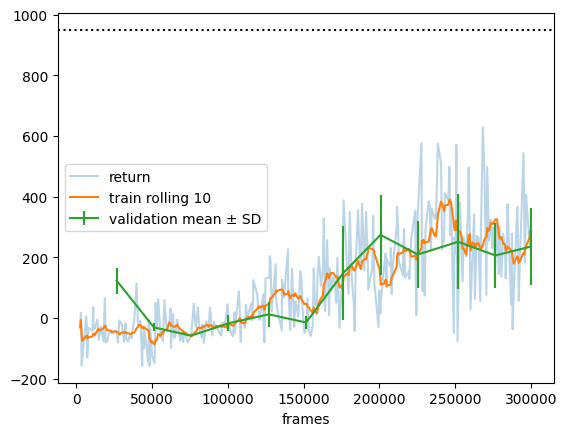

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
train = pd.read_csv(run/'train.csv')
val = pd.read_csv(run/'eval.csv')
ax = train.plot(x='frames', y='return', alpha=.3)
ax.plot(train.frames,train['return'].rolling(10,min_periods=1).mean(),label='train rolling 10')
ax.errorbar(val.frames,val.score,yerr=val['std'],label='validation mean ± SD')
ax.axhline(950,color='black',linestyle=':')
ax.legend()
plt.show()

## 4. 평가 및 주행 영상
제출용 ONNX로 공개 seed 1000–1009를 달립니다. 96×96 원본 관측 한 장이 영상 한 프레임이며 CSV의 video_s와 대응합니다. 차 옆의 녹색 비율로 이탈·복귀를 추정합니다. 타일 수는 평가 중 실제 방문 카운터를 읽습니다. 득점 재개는 복귀 후 다음 이탈 전에 새 타일 방문이 기록된 프레임이 3개 이상인 경우입니다. 경계와 커브에서는 영상을 함께 확인하세요. image_change는 화면 변화량이며 실제 속도 단위와 다릅니다.

In [10]:
import json
from evaluate import load_agent
from export import export, verify
team = 'Reinforcement_material'
onnx_path = run / (team + '_beta.onnx')
agent = load_agent(str(run/'best.pt'), torch.device('cpu'))
export(agent, str(onnx_path))
rate, steps = verify(agent, str(onnx_path))
print(f'행동 일치율 {rate:.1%} ({steps} steps)')
if rate < .95:
    raise RuntimeError('행동 일치율 기준 미달')

행동 일치율 100.0% (241 steps)


In [11]:
import csv
from collections import deque
from contextlib import closing
from moviepy import ImageSequenceClip
import check_submission as grader

out = run / 'diagnostics'
out.mkdir(exist_ok=True)
sess, cfg = grader.load_policy(str(onnx_path))
def grass_fraction(rgb):
    # Sample strips beside the car, clear of its sprite and dashboard.
    left = rgb[66:76, 39:43].astype(int)
    right = rgb[66:76, 53:57].astype(int)
    red, green, blue = np.concatenate((left,right),axis=1).transpose(2,0,1)
    return float(((green > red + 25) & (green > blue + 25)).mean())

def record_seed(seed):
    env = grader.HideScoreText(gym.make('CarRacing-v3', continuous=True))
    rows, images = [], []
    hints = deque(maxlen=5)
    total = 0.
    last_gain = decision = 0
    off = done = False
    try:
        obs, _ = env.reset(seed=seed)
        stack = deque([obs]*cfg['n_stack'], maxlen=cfg['n_stack'])
        while not done:
            raw = sess.run(['action'], {'frames': np.stack(stack)[None]})[0]
            action = grader.to_env_action(raw, cfg, env)
            decision += 1
            for _ in range(cfg['frame_skip']):
                before = obs
                tiles_before = int(env.unwrapped.tile_visited_count)
                obs, reward, term, trunc, _ = env.step(action)
                tiles = int(env.unwrapped.tile_visited_count)
                frame = len(rows)+1
                total += reward
                if tiles > tiles_before:
                    last_gain = frame
                grass = grass_fraction(obs)
                hints.append(grass)
                previous = off
                if len(hints)==5 and frame >= 60:  # ignore startup camera zoom
                    if min(hints) > .65:
                        off = True
                    elif max(hints) < .25:
                        off = False
                event = ('grass_entry' if off else 'road_return') if off != previous else ''
                motion = np.abs(obs[:80].astype(int)-before[:80].astype(int)).mean()
                rows.append(dict(seed=seed,frame=frame,video_s=(frame-1)/50,
                    decision=decision,steer=action[0],gas=action[1],brake=action[2],
                    tiles_before=tiles_before, tiles_visited=tiles, new_tiles=tiles-tiles_before,
                    reward=reward,score=total,frames_since_gain=frame-last_gain,
                    image_change=motion,grass_fraction=grass,offroad_hint=int(off),
                    event=event,terminated=term,truncated=trunc))
                images.append(obs.copy())
                done = term or trunc
                if done:
                    break
            stack.append(obs)
    finally:
        env.close()
    stem = out/f'seed_{seed}'
    trace = pd.DataFrame(rows)
    trace.to_csv(stem.with_suffix('.csv'), index=False)
    events = recovery_events(trace)
    # Report tiles strictly before the first frame in the 5-frame entry confirmation window.
    first_tiles = rows[events[0]['entry_frame'] - 5]['tiles_before'] if events else None
    resumed = sum(e['progress_resumed'] for e in events)
    with closing(ImageSequenceClip(images, fps=50)) as clip:
        clip.write_videofile(str(stem.with_suffix('.mp4')), codec='libx264', audio=False,logger=None)
    return dict(seed=seed,score=total,frames=len(rows),grass_entries=sum(r['event']=='grass_entry' for r in rows),
                first_exit_tiles=first_tiles, total_tiles=rows[-1]['tiles_visited'],
                resumed_events=resumed, progress_resume_rate=resumed/len(events) if events else None,
                grass_frames=sum(r['offroad_hint'] for r in rows),max_frames_without_gain=max(r['frames_since_gain'] for r in rows))
summary = pd.DataFrame([record_seed(seed) for seed in range(1000,1010)])
summary.to_csv(out/'summary.csv',index=False)
display(summary.sort_values('score'))
from IPython.display import Video, display
worst = int(summary.loc[summary.score.idxmin(),'seed'])
display(Video(str(out/f'seed_{worst}.mp4'),embed=True,width=384))

,seed,score,frames,grass_entries,first_exit_tiles,total_tiles,resumed_events,progress_resume_rate,grass_frames,max_frames_without_gain
0,1000,-15.312628,963,1,53,53,0,0.000000,755,765
5,1005,65.644172,1000,1,54,54,0,0.000000,787,799
7,1007,200.970874,1000,4,23,93,2,0.500000,385,242
2,1002,205.454545,1000,1,84,84,0,0.000000,687,694
3,1003,210.000000,1000,2,23,93,1,0.500000,643,419
8,1008,216.455696,1000,1,99,100,0,0.000000,674,677
6,1006,232.142857,1000,2,23,93,1,0.500000,664,456
4,1004,269.127517,1000,3,35,110,2,0.666667,479,242
9,1009,277.777778,1000,2,23,102,1,0.500000,607,403
1,1001,329.487179,1000,1,134,134,0,0.000000,586,593


gae | 평균 점수 199.17 | 무이탈 0/10 | 첫 이탈 전 타일 평균 55.1 (이탈 트랙 10개) | 득점 재개 7/18 (38.9%)


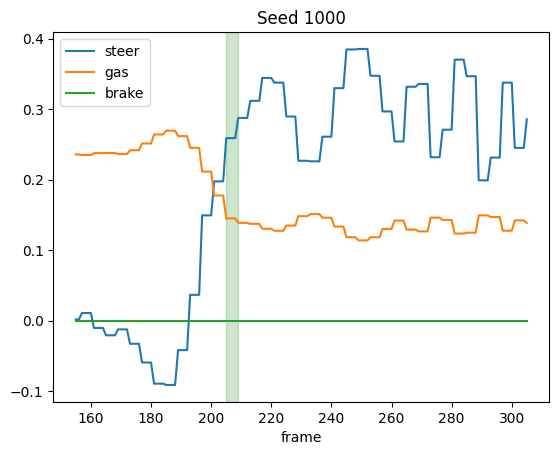

In [12]:
import matplotlib.pyplot as plt
for label in VARIANTS.values():
    path = run.parent / f'BetaPPO_Gray84_s42_{label}' / 'diagnostics' / 'summary.csv'
    if path.is_file():
        metrics = pd.read_csv(path)
        exits = metrics.grass_entries.sum()
        resumed = metrics.resumed_events.sum()
        rate = f'{resumed/exits:.1%}' if exits else 'N/A'
        first = metrics.first_exit_tiles.dropna()
        print(f'{label} | 평균 점수 {metrics.score.mean():.2f} | 무이탈 {metrics.first_exit_tiles.isna().sum()}/10'
              f' | 첫 이탈 전 타일 평균 {first.mean():.1f} (이탈 트랙 {len(first)}개)'
              f' | 득점 재개 {resumed}/{exits} ({rate})')

# Plot the first departure on the selected track. The shaded window is the entry detector's confirmation.
PLOT_SEED = worst  # Set to 1000, for example, to compare the same track across runs.
trace = pd.read_csv(out / f'seed_{PLOT_SEED}.csv')
entries = trace.loc[trace.event.eq('grass_entry'), 'frame']
if not entries.empty:
    onset = int(entries.iloc[0]) - 4
    window = trace[trace.frame.between(onset-50, onset+100)]
    ax = window.plot(x='frame', y=['steer','gas','brake'], title=f'Seed {PLOT_SEED}')
    ax.axvspan(onset, onset+4, alpha=.2, color='green')
    plt.show()


In [13]:
events = [event for seed in range(1000,1010)
          for event in recovery_events(pd.read_csv(out/f'seed_{seed}.csv'))]
event_table = pd.DataFrame(events, columns=['seed','entry_frame','video_s','returned',
                                           'progress_resumed','frames_to_progress'])
event_table.to_csv(out/'recovery_events.csv', index=False)
display(event_table)


,seed,entry_frame,video_s,returned,progress_resumed,frames_to_progress
0,1000,209,4.16,0,0,NaN
1,1001,415,8.28,0,0,NaN
2,1002,314,6.26,0,0,NaN
3,1003,123,2.44,1,1,245.0
4,1003,586,11.70,0,0,NaN
5,1004,161,3.20,1,1,234.0
6,1004,558,11.14,1,1,132.0
7,1004,770,15.38,1,0,NaN
8,1005,214,4.26,0,0,NaN
9,1006,124,2.46,1,1,232.0


## 5. 리더보드 제출 파일 만들기
공식 공개 20트랙 성적과 영상 10개의 점수를 대조하고 목표 달성 여부를 출력합니다.

In [14]:
subprocess.run([sys.executable, 'check_submission.py', '--onnx', str(onnx_path),
                '--seeds', '1000-1019', '--json', str(run/'public_eval.json')], check=True)
scores = json.loads((run/'public_eval.json').read_text())
np.testing.assert_allclose(scores['returns'][:10], summary.score, atol=1e-5, rtol=0)
print(f"공개 20트랙 평균 {scores['mean']:.2f} / 최저 {min(scores['returns']):.2f} / 950 이상 {sum(v>=950 for v in scores['returns'])}/20")
print('공개 평균 목표 달성' if scores['mean']>=950 else '공개 평균 목표 미달')
config = json.loads((run/'config.json').read_text())
assert config['config']['td_steps'] == TD_STEPS
assert config['budget'] == 300000 and config['agent'] == 'beta_ppo' and config['seed'] == 42
submission = run / (team + '_submission.zip')
with zipfile.ZipFile(submission, 'w', zipfile.ZIP_DEFLATED) as archive:
    for name in [*manifest, 'agents/beta_ppo.py','four_env.py']:
        archive.write(root/name, name)
    for name in ['config.json','train.csv','eval.csv','best.pt','public_eval.json']:
        archive.write(run/name, 'runs/beta_ppo_s42/'+name)
    archive.write(onnx_path, onnx_path.name)
    archive.writestr('REPRODUCE.txt', f'pip install -r requirements.txt\npython train.py --agent beta_ppo --seed 42 --td-steps {TD_STEPS} --budget 300000 --eval-every 25000 --run-dir runs/beta_ppo_s42\n')
print(submission)
files.download(str(submission))

공개 20트랙 평균 205.62 / 최저 -25.68 / 950 이상 0/20
공개 평균 목표 미달
/content/drive/MyDrive/CarRacing/BetaPPO_Gray84_s42_gae/Reinforcement_material_submission.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>